## Labels and a model

`probatum.labels` gives every bar what one trade decided at its close would have made
through the same fill model a backtest runs, with a stop, a take-profit and a horizon, and
the bar its trade ended on. A scikit-learn model fits those labels on features, validated
with folds purged by where each trade ended, and its predictions are traded as weights. A
feature that reads a bar not yet closed is refused before anything is fitted. Hourly Bitcoin
bars of 2024 and 2025.

In [1]:
import pathlib

import exchange_router
import matplotlib.pyplot
import numpy
import pandas
import probatum
import sklearn
import sklearn.ensemble

matplotlib.pyplot.style.use(style="../oceano.mplstyle")

print(f"probatum {probatum.__version__}, exchange-router {exchange_router.__version__}, "
      f"scikit-learn {sklearn.__version__}")

probatum 4.0.0, exchange-router 4.0.0, scikit-learn 1.9.1


### The bars

In [2]:
PATH = pathlib.Path("../bars/binance-spot-btcusdt-1h-2024-2025")

if PATH.exists():
    data = probatum.Data.load(path=PATH)
else:
    with exchange_router.Router.local(exchanges=["binance"]) as router:
        data = probatum.Data.from_router(router, exchange="binance", market="spot",
                                         interval="1h", symbols=["BTCUSDT"],
                                         start="2024-01-01", end="2025-12-31")
    data.save(path=PATH)

data

Data(BTCUSDT, 1h, 17544 bars from 2024-01-01 00:00 to 2025-12-31 23:00)

### The labels

A trade of 10,000 USDT bought at the next open after each close, a stop and a take-profit
3% away, closed after 24 bars if neither filled, net of every cost. Each label's `weight`
is its uniqueness among the trades that overlap it, a fit's sample weight.

In [3]:
labels = probatum.labels(data, venue="binance_spot", horizon=24, notional=10_000.0,
                         stop=0.03, take_profit=0.03)

exits = pandas.Series(labels.exit[:, 0]).replace(to_replace="", value="no label")

print(labels)
print(exits.value_counts().to_string())
print(f"mean return {numpy.nanmean(labels.ret) * 100:.3f}%, "
      f"mean uniqueness {numpy.nanmean(labels.weight):.3f}")

Labels(BTCUSDT over 17544 bars, long 10,000.0 at a horizon of 24)


horizon        10872
stop            3342
take_profit     3305
censored          24
no label           1
mean return -0.170%, mean uniqueness 0.055


### The features

A function of a Data returning `(T, N, F)`: two returns, the RSI, the volatility of the
last day against that of the last week, and the close's z-score. Every one reads only bars
that had closed.

In [4]:
def features(data):
    close   = data.closes
    returns = numpy.log(close / probatum.ta.shift(close))
    return numpy.stack([probatum.ta.roc(close, length=24),
                        probatum.ta.roc(close, length=24 * 7),
                        probatum.ta.rsi(close, length=14),
                        probatum.ta.stdev(returns, length=24)
                        / probatum.ta.stdev(returns, length=24 * 7),
                        probatum.ta.zscore(close, length=24 * 3)], axis=-1)


print(features(data).shape)

(17544, 1, 5)


### The model, validated

Five folds in order, each fitted on the others with the rows whose trade reaches the test
span purged, and an embargo after it of the longest label. A fresh estimator for every fit.
Each prediction becomes a weight: a predicted return of a third of a percent or more holds
the whole account, and nothing below zero holds nothing.

In [5]:
def to_weights(predicted):
    return numpy.clip(predicted * 300.0, a_min=0.0, a_max=1.0)


model = sklearn.ensemble.HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05,
                                                       max_depth=3, random_state=0)

study = probatum.validate(model, data=data, venue="binance_spot",
                          cv=probatum.cv.PurgedKFold(k=5), features=features,
                          labels=labels, to_weights=to_weights, holdout=0.2)

study.summary()

,value,low,high,level,method,why_none
paths,1,,,,,
score,-2.64,-4.32,-0.96,0.95,"delta method, Newey-West lag 30",
windows,5,,,,,
windows_gained,0,,,,,
decay,,,,,,1
decay_error,,,,,,1
rank_ic,-0.00,,,,,
rank_ic_t,-0.08,,,,,
costs,"8,137",,,,,
price_pnl,"2,404",,,,,


### Its skill apart from the costs

Each path's forecast is Spearman's correlation of its predictions with its labels' returns,
the rank IC, with a Newey-West standard error over the bars.

In [6]:
print(study.forecast)

study.fits.to_pandas()[["number", "test", "train", "purged", "embargoed", "rows",
                        "dropped"]]

           rank_ic     error         t  lag  r_squared   rows  paths
Forecast -0.001967  0.024035 -0.081857   25  -0.037641  13842      1


,number,test,train,purged,embargoed,rows,dropped
0,0,0 to 2806,11154,25,24,11154,0
1,1,2807 to 5613,11129,50,24,10961,168
2,2,5614 to 8420,11150,29,24,10982,168
3,3,8421 to 11227,11139,40,24,10971,168
4,4,11228 to 14034,11204,24,0,11036,168


### What the folds traded

The path's equity from its returns, beside buying and holding the same bars.

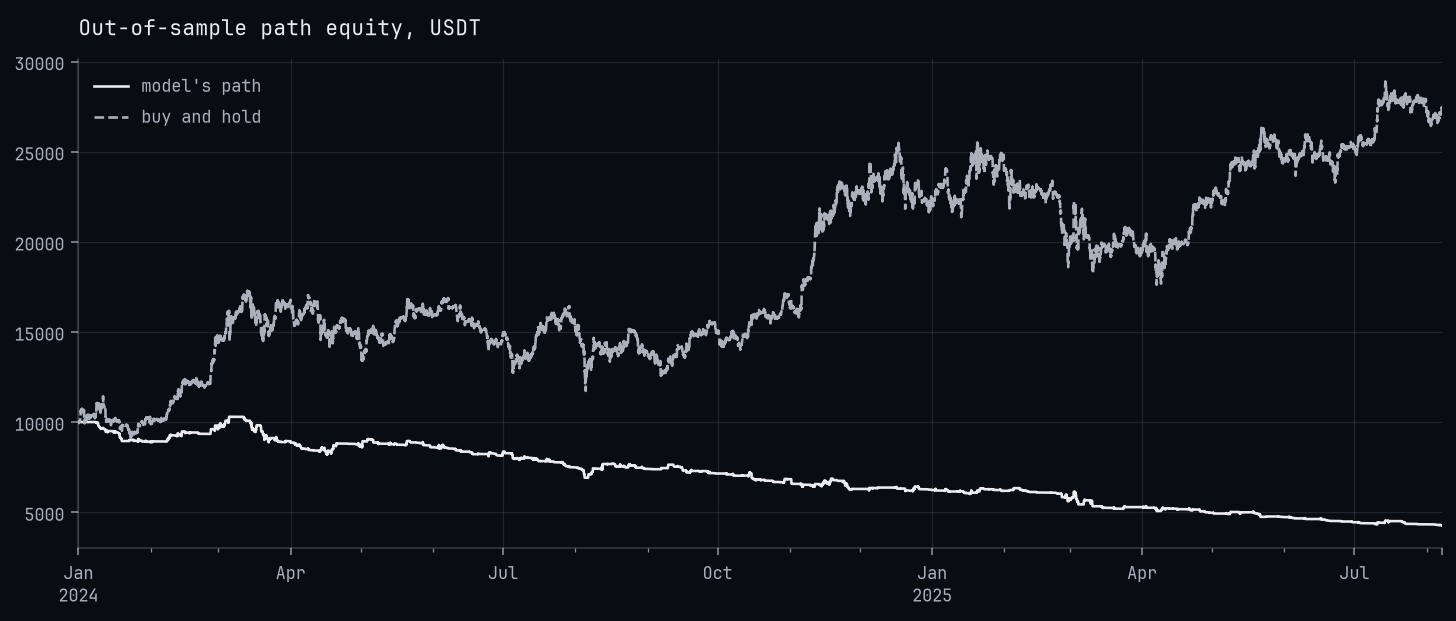

In [7]:
times  = pandas.to_datetime(data.time[:study.returns.shape[1]], utc=True)
equity = pandas.DataFrame(
    {"model's path": 10_000.0 * numpy.cumprod(1.0 + numpy.nan_to_num(study.returns[0])),
     "buy and hold": 10_000.0 * data.close[:len(times)] / data.close[0]}, index=times)

axes = equity.plot(title="Out-of-sample path equity, USDT", xlabel="")
matplotlib.pyplot.show()

### A feature that reads ahead

The same features with one more: an average of the 48 closes centred on each bar, which
reads 24 bars that had not closed. `validate` computes the features again on the bars cut
after each of up to ten rows, finds the value that moved, and refuses the features before
anything is fitted.

In [8]:
def ahead(data):
    centred = pandas.Series(data.closes[:, 0]).rolling(window=48, center=True).mean()
    return numpy.concatenate([features(data), centred.to_numpy()[:, None, None]], axis=-1)


try:
    probatum.validate(model, data=data, venue="binance_spot",
                      cv=probatum.cv.PurgedKFold(k=5), features=ahead, labels=labels,
                      to_weights=to_weights, holdout=0.2)
except probatum.LookaheadError as error:
    print(f"{type(error).__name__}: {error}")

LookaheadError: features: feature 5 of BTCUSDT at row 1,380 (2024-02-27 12:00) is 56049.74562499999 on the whole Data and nan on the Data cut after row 1,402; compute each row's features from the bars up to it
